# Centred map

In [2]:
import numpy as np 
import torch
import matplotlib.pyplot as plt
from cosmology import Cosmology
from nfw import NFWHalo
from lensing import shear_profile

cosmology = Cosmology()
M200c = 1e15
c200c = 4.0
z_lens = 0.3
z_source = 1.0

centre = (0.0, 0.0)

theta = [np.log10(M200c), c200c, centre[0], centre[1], z_lens, z_source]

halo = NFWHalo(
    theta=theta,
    z_l=0.3,              # Lens redshift
    cosmology=cosmology,
)

r_s, rho_s = halo.nfw_parameters()
# Choose 30 projected physical radii from 0.1 to 3 Mpc.
R = np.geomspace(0.1, 3.0, 30)

Sigma, Sigma_mean = halo.surface_densities(R)
DeltaSigma = Sigma_mean - Sigma

Sigma_crit = cosmology.critical_surface_density(z_lens, z_source)
g_t = shear_profile(
    theta=theta,
    R=R,
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
)

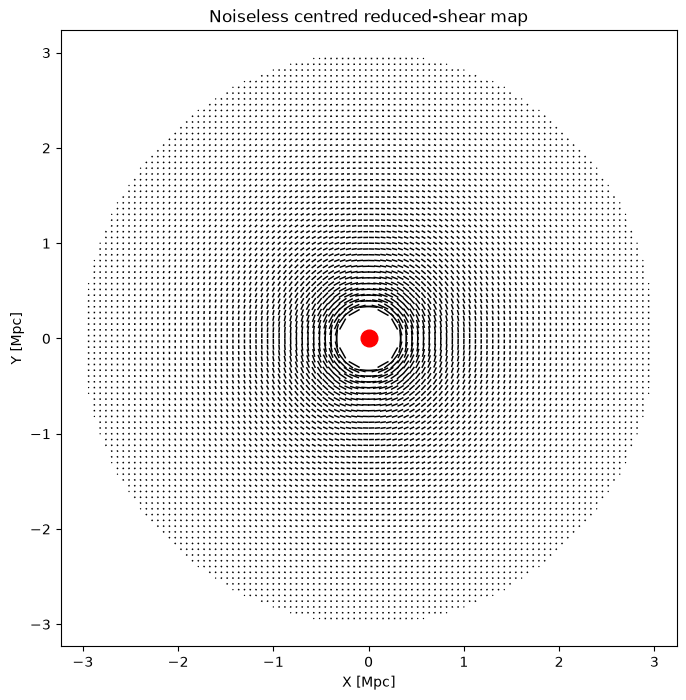

In [4]:
#Choose positions and calculate their geometry
axis = np.linspace(-3.0, 3.0, 100)
x, y = np.meshgrid(axis, axis)

xc, yc = centre
dx, dy = x - xc, y - yc

R = np.hypot(dx, dy)
phi = np.arctan2(dy, dx)
mask = (R >= 0.3) & (R <= 3.0)

gt_map = np.zeros_like(R)
gt_map[mask] = shear_profile(
    theta=theta,
    R=R[mask],
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
)

g1 = -gt_map * np.cos(2 * phi)
g2 = -gt_map * np.sin(2 * phi)

amplitude = np.hypot(g1, g2)
orientation = 0.5 * np.arctan2(g2, g1)  # orientation of the shear in radians

u = amplitude * np.cos(orientation)
v = amplitude * np.sin(orientation)

fig, ax = plt.subplots(figsize=(8, 8))
ax.quiver(
    x[mask], y[mask], u[mask], v[mask],
    angles='xy', scale_units='xy', scale=1,
    pivot="middle",
    headwidth=0, headlength=0, headaxislength=0
    )
ax.plot(xc, yc, 'ro', markersize=12, label='Halo Center')
ax.set(
    xlabel='X [Mpc]', ylabel='Y [Mpc]',
    title="Noiseless centred reduced-shear map",
    aspect='equal'
)
plt.show()

In [ ]:
#Check that conversion works

gt_recovered = -g1 * np.cos(2 * phi) - g2 * np.sin(2 * phi)
gx_recovered = -g1 * np.sin(2 * phi) + g2 * np.cos(2 * phi)

np.testing.assert_allclose(gt_recovered[mask], gt_map[mask], rtol=1e-12, atol=1e-14)
np.testing.assert_allclose(gx_recovered[mask], 0.0, atol=1e-14)
print("Conversion checks passed.")
print(
    "Maximum tangential reconstruction error:",
    np.max(np.abs(gt_recovered[mask] - gt_map[mask]))
)
print(
    "Maximum absolute cross component:",
    np.max(np.abs(gx_recovered[mask]))
)

Conversion checks passed.
Maximum tangential reconstruction error: 2.7755575615628914e-17
Maximum absolute cross component: 6.938893903907228e-18


# Displaced-centre geometry

In [ ]:
true_centre = (0.4, -0.2)
assumed_centre = (0.0, 0.0)

axis = np.linspace(-3.0, 3.0, 100)
x, y = np.meshgrid(axis, axis)

#Relative to true halo centre
dx_true = x - true_centre[0]
dy_true = y - true_centre[1]

R_true = np.hypot(dx_true, dy_true)
phi_true = np.arctan2(dy_true, dx_true)

#Relative to assumed halo centre
dx_assumed = x - assumed_centre[0]
dy_assumed = y - assumed_centre[1]

R_assumed = np.hypot(dx_assumed, dy_assumed)
phi_assumed = np.arctan2(dy_assumed, dx_assumed)

mask = (
    (R_assumed >= 0.3)
    & (R_assumed <= 3.0)
    & (R_true >= 0.3)
)

gt_map = np.zeros_like(R_true)
gt_map[mask] = shear_profile(
    theta=theta,
    R=R_true[mask],
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
)

# Generate the physical field around the true halo centre.
g1 = -gt_map * np.cos(2 * phi_true)
g2 = -gt_map * np.sin(2 * phi_true)

gt_assumed = -g1 * np.cos(2 * phi_assumed) - g2 * np.sin(2 * phi_assumed)
gx_assumed = -g1 * np.sin(2 * phi_assumed) + g2 * np.cos(2 * phi_assumed)

# Recompute plotting sticks from the displaced field.
amplitude = np.hypot(g1, g2)
orientation = 0.5 * np.arctan2(g2, g1)
u = amplitude * np.cos(orientation)
v = amplitude * np.sin(orientation)

fig, ax = plt.subplots(figsize=(8, 8))
ax.quiver(
    x[mask], y[mask], u[mask], v[mask],
    angles='xy', scale_units='xy', scale=1,
    pivot="middle",
    headwidth=0, headlength=0, headaxislength=0
    )
ax.plot(*true_centre, "ro", label="True halo centre")
ax.plot(*assumed_centre, "bx", markersize=10, label="Assumed centre")
ax.set_title("Noiseless displaced-centre reduced-shear map")
ax.legend()
plt.show()

In [ ]:
gt_true = (
    -g1 * np.cos(2 * phi_true)
    - g2 * np.sin(2 * phi_true)
)
gx_true = (
    -g1 * np.sin(2 * phi_true)
    + g2 * np.cos(2 * phi_true)
)

np.testing.assert_allclose(
    gt_true[mask], gt_map[mask], rtol=1e-12, atol=1e-14
)
np.testing.assert_allclose(gx_true[mask], 0.0, atol=1e-14)

print("True-centre checks passed.")
print("Maximum |gx| around assumed centre:",
      np.max(np.abs(gx_assumed[mask])))